# Exploratory Analysis - TissueMNIST

Purpose: Initial exploration of TissueMNIST dataset for retrieval benchmark study



## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import sys
import os

# Add src to path so we can import our modules
sys.path.append('..')
from src.data_loader import TissueMNISTLoader

# Set visualization style
sns.set_theme(style="whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.dpi'] = 100

# Create results directories
Path("../results/figures").mkdir(parents=True, exist_ok=True)
Path("../results/metrics").mkdir(parents=True, exist_ok=True)
Path("../data/processed").mkdir(parents=True, exist_ok=True)

print("✓ Setup complete")

✓ Setup complete


## 2. Load Dataset

In [58]:
# Load TissueMNIST
loader = TissueMNISTLoader(data_root='../data/raw')

# Get basic info
info = loader.get_split_info()

print("="*70)
print("DATASET OVERVIEW")
print("="*70)
print(f"Dataset: {info['dataset_name']}")
print(f"Total images: {info['total_size']:,}")
print(f"  - Training:   {info['train_size']:,}")
print(f"  - Validation: {info['val_size']:,}")
print(f"  - Test:       {info['test_size']:,}")
print(f"\nImage shape: {info['image_shape']}")
print(f"Number of classes: {info['n_classes']}")
print(f"\nClass names:")
for class_id, name in info['class_names'].items():
    print(f"  {class_id}: {name}")

Loading TissueMNIST dataset...
  Extracting training data...
  Extracting validation data...
  Extracting test data...
✓ Loaded 165,466 train, 23,640 val, 47,280 test images
DATASET OVERVIEW
Dataset: TissueMNIST
Total images: 236,386
  - Training:   165,466
  - Validation: 23,640
  - Test:       47,280

Image shape: (28, 28)
Number of classes: 8

Class names:
  0: Collecting Duct, Connecting Tubule
  1: Distal Convoluted Tubule
  2: Glomerular endothelial cells
  3: Interstitial endothelial cells
  4: Leukocytes
  5: Podocytes
  6: Proximal Tubule Segments
  7: Thick Ascending Limb


## 3. Sample Images Visualization

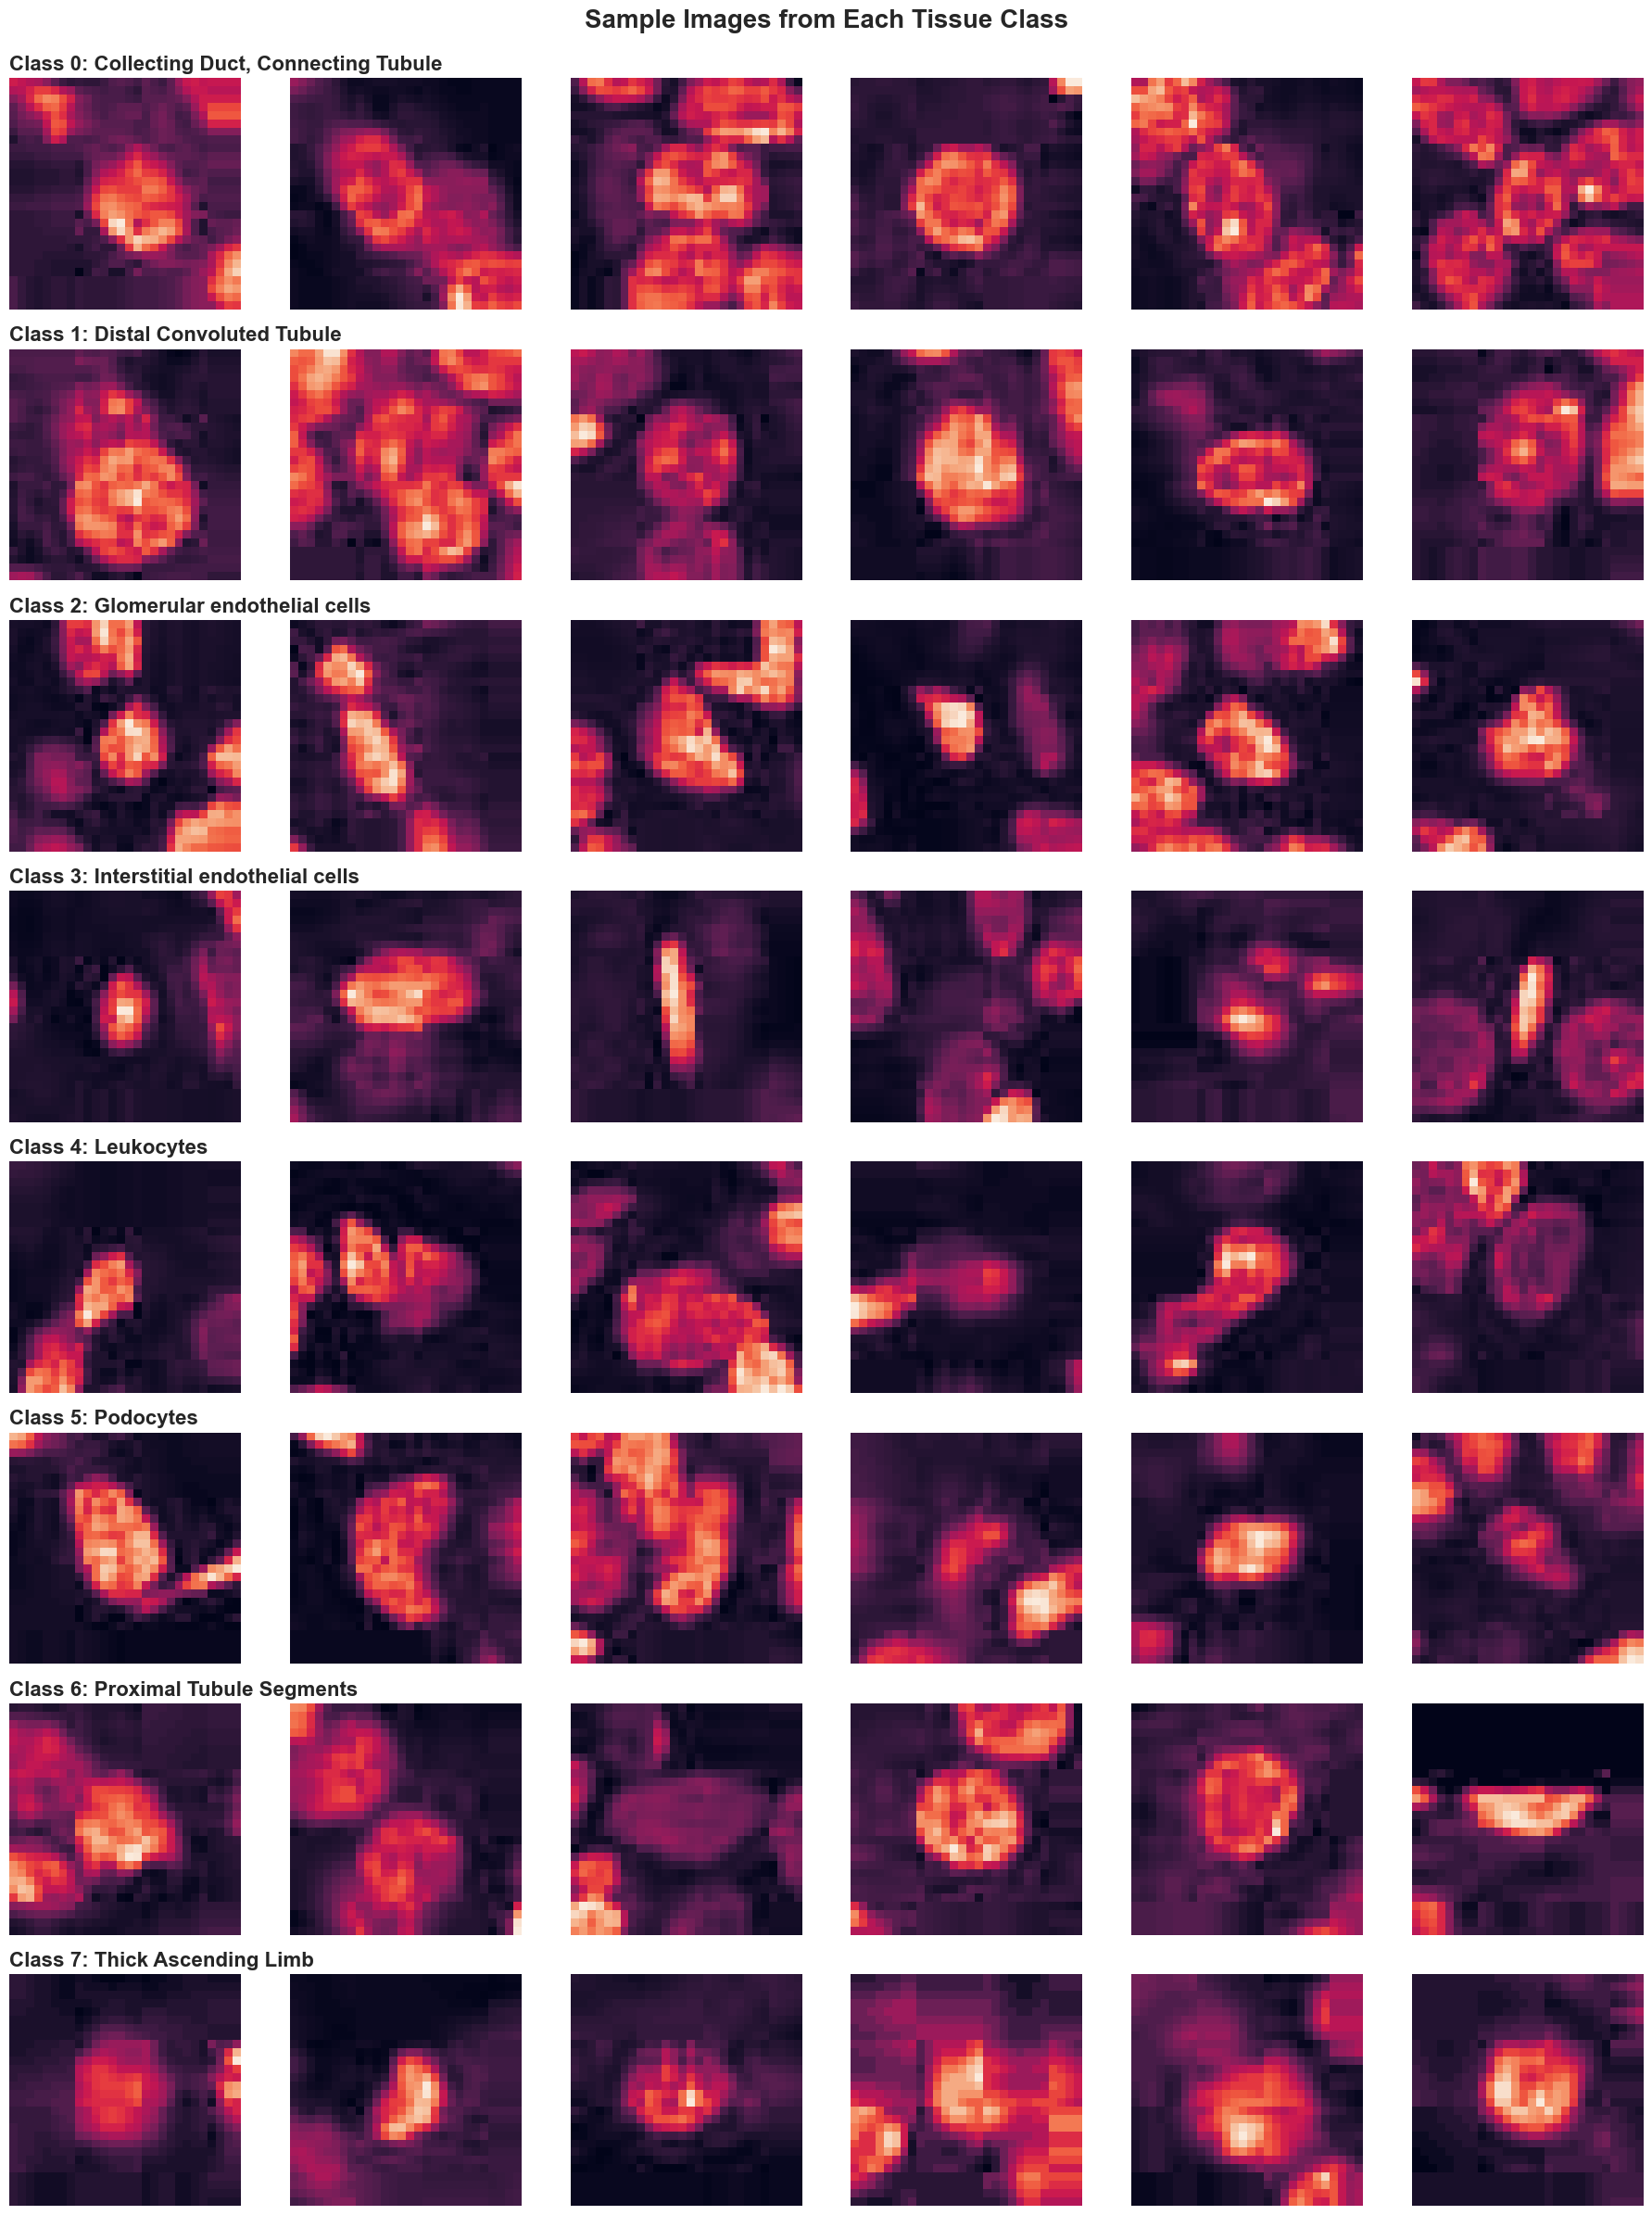

✓ Saved: results/figures/sample_images.png


In [59]:
# Show sample images from each class
fig, axes = plt.subplots(8, 6, figsize=(18, 24))
fig.suptitle('Sample Images from Each Tissue Class', 
             fontsize=20, fontweight='bold', y=0.995)

for class_id in range(loader.n_classes):
    # Get 6 random samples
    samples, _ = loader.get_samples_by_class(class_id, split='train', n_samples=6)
    class_name = loader.class_names[str(class_id)]
    
    for col in range(6):
        ax = axes[class_id, col]
        ax.imshow(samples[col])
        ax.axis('off')
        
        if col == 0:
            ax.set_title(f'Class {class_id}: {class_name}', 
                        fontsize=16, fontweight='bold', loc='left')

plt.tight_layout()
plt.savefig('../results/figures/sample_images.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: results/figures/sample_images.png")

## 4. Class Distribution Analysis

In [61]:
# Get distributions for each split
train_dist = loader.get_class_distribution('train')
val_dist = loader.get_class_distribution('val')
test_dist = loader.get_class_distribution('test')

# Calculate imbalance
max_count = max(train_dist.values())
min_count = min(train_dist.values())
imbalance_ratio = max_count / min_count

print("="*70)
print("CLASS DISTRIBUTION ANALYSIS")
print("="*70)
print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1")
print(f"Most common class: {max_count:,} samples")
print(f"Rarest class: {min_count:,} samples")
print("\nTraining set distribution:")

for class_id in sorted(train_dist.keys()):
    count = train_dist[class_id]
    pct = (count / sum(train_dist.values())) * 100
    class_name = loader.class_names[str(class_id)]
    bar = "█" * int(pct / 2)
    print(f"Class {class_id} | {class_name[:35]:35s} | {count:6,} ({pct:5.2f}%) {bar}")

CLASS DISTRIBUTION ANALYSIS
Imbalance Ratio: 9.05:1
Most common class: 53,075 samples
Rarest class: 5,866 samples

Training set distribution:
Class 0 | Collecting Duct, Connecting Tubule  | 53,075 (32.08%) ████████████████
Class 1 | Distal Convoluted Tubule            |  7,814 ( 4.72%) ██
Class 2 | Glomerular endothelial cells        |  5,866 ( 3.55%) █
Class 3 | Interstitial endothelial cells      | 15,406 ( 9.31%) ████
Class 4 | Leukocytes                          | 11,789 ( 7.12%) ███
Class 5 | Podocytes                           |  7,705 ( 4.66%) ██
Class 6 | Proximal Tubule Segments            | 39,203 (23.69%) ███████████
Class 7 | Thick Ascending Limb                | 24,608 (14.87%) ███████


## 4. Visualization - Distribution Across Splits

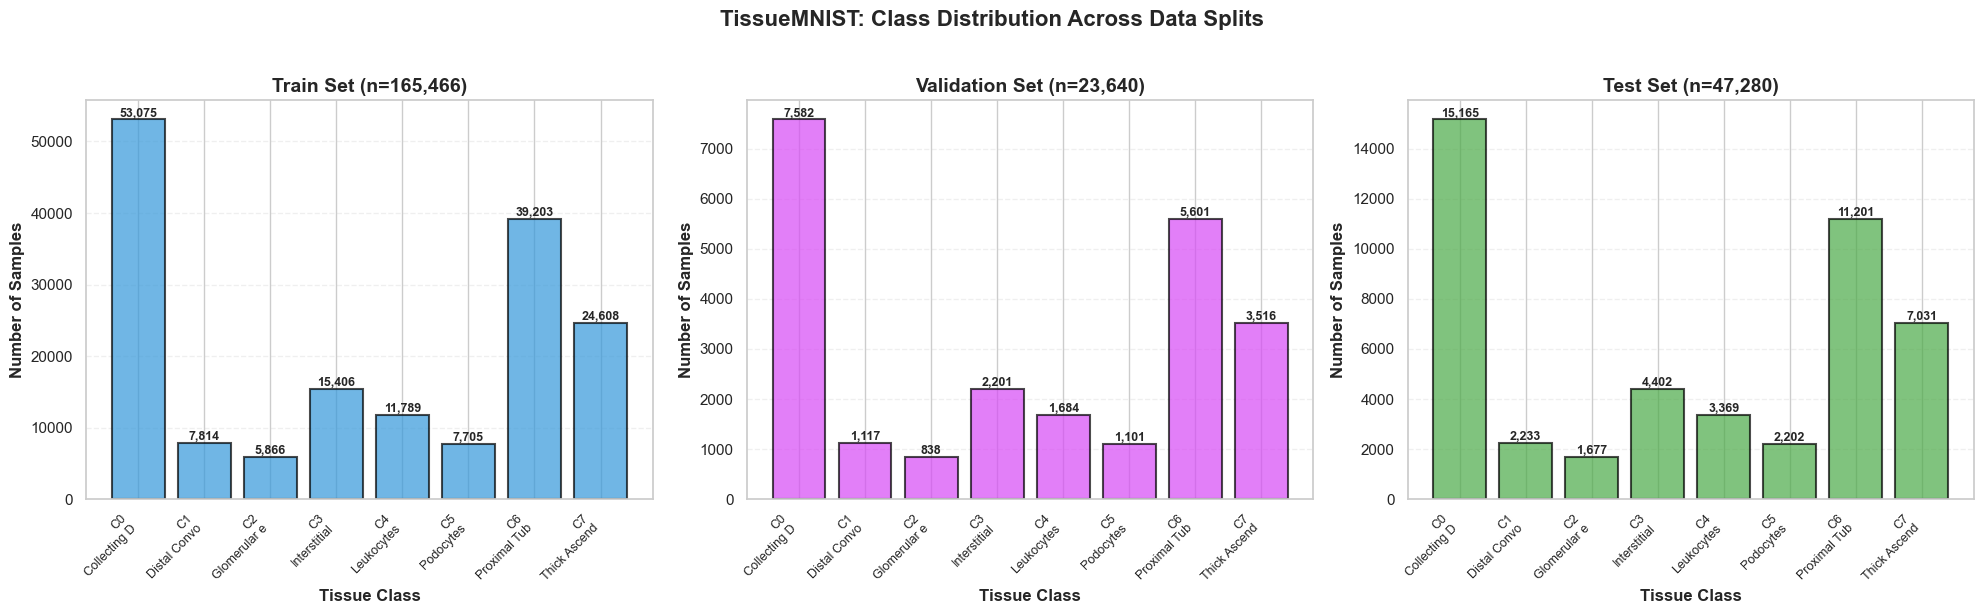

✓ Saved: results/figures/class_distribution.png


In [62]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('TissueMNIST: Class Distribution Across Data Splits', 
             fontsize=16, fontweight='bold', y=1.02)

splits = [('Train', train_dist), ('Validation', val_dist), ('Test', test_dist)]
colors = ['#3498db', "#d749f6", "#4baa47"]

for ax, (split_name, dist), color in zip(axes, splits, colors):
    classes = sorted(dist.keys())
    counts = [dist[c] for c in classes]
    class_labels = [f"C{c}\n{loader.class_names[str(c)][:12]}" for c in classes]
    
    bars = ax.bar(range(len(classes)), counts, color=color, alpha=0.7, 
                   edgecolor='black', linewidth=1.5)
    
    ax.set_xlabel('Tissue Class', fontsize=12, fontweight='bold')
    ax.set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
    ax.set_title(f'{split_name} Set (n={sum(counts):,})', 
                 fontsize=14, fontweight='bold')
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(class_labels, rotation=45, ha='right', fontsize=9)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    
    # Add count labels
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{count:,}', ha='center', va='bottom', 
                fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: results/figures/class_distribution.png")

## 6. Imbalance Visualiztion

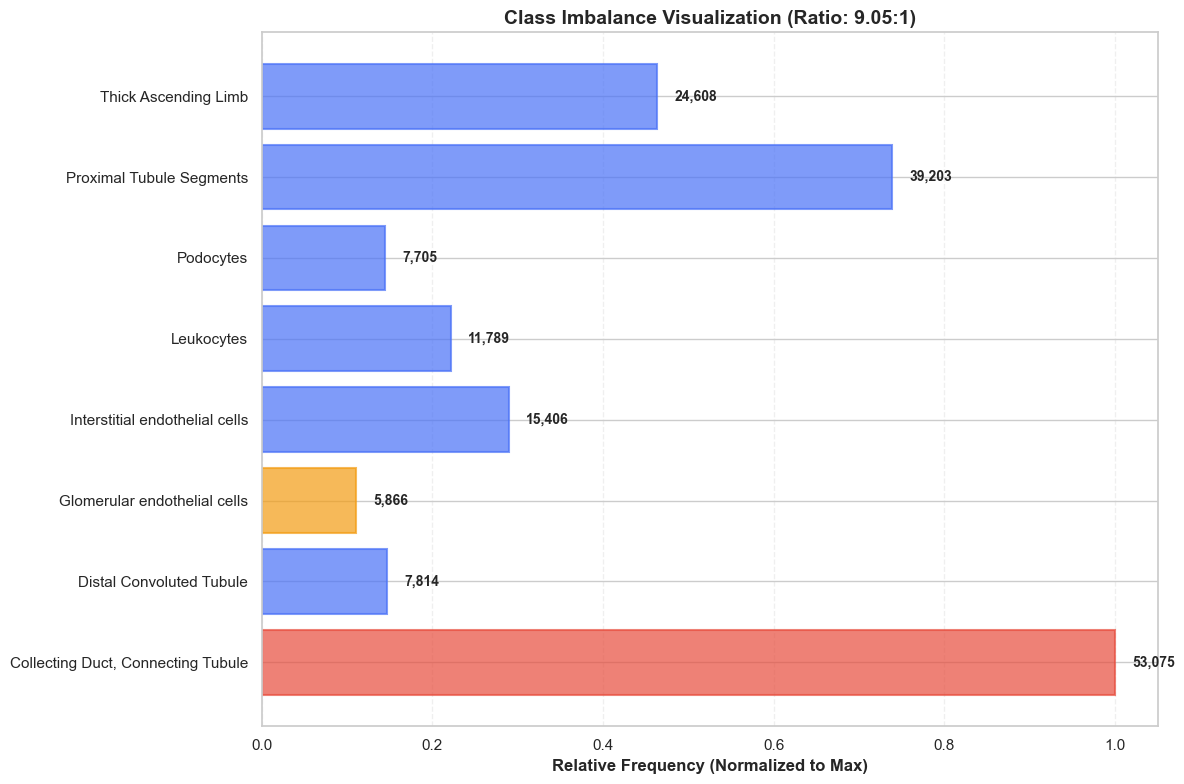

✓ Saved: results/figures/class_imbalance.png


In [63]:
fig, ax = plt.subplots(figsize=(12, 8))

classes = sorted(train_dist.keys())
counts = [train_dist[c] for c in classes]
class_labels = [loader.class_names[str(c)][:35] for c in classes]

# Normalize to show relative imbalance
normalized_counts = [c / max(counts) for c in counts]

bars = ax.barh(range(len(classes)), normalized_counts, 
               alpha=0.7, edgecolor='black', linewidth=1.5)

# Color by imbalance severity
for i, (bar, count) in enumerate(zip(bars, counts)):
    if count == max(counts):
        bar.set_color('#e74c3c')  # Red for most common
    elif count == min(counts):
        bar.set_color('#f39c12')  # Orange for rarest
    else:
        bar.set_color("#4971f7")  # Blue for middle

ax.set_yticks(range(len(classes)))
ax.set_yticklabels(class_labels, fontsize=11)
ax.set_xlabel('Relative Frequency (Normalized to Max)', fontsize=12, fontweight='bold')
ax.set_title(f'Class Imbalance Visualization (Ratio: {imbalance_ratio:.2f}:1)', 
             fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3, linestyle='--')

# Add actual counts
for i, (bar, count) in enumerate(zip(bars, counts)):
    width = bar.get_width()
    ax.text(width + 0.02, bar.get_y() + bar.get_height()/2,
            f'{count:,}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/class_imbalance.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: results/figures/class_imbalance.png")

## 7. Statistical Summary

In [78]:
# Create a summary statistics table

summary_data = []
for class_id in sorted(train_dist.keys()):
    class_name = loader.class_names[str(class_id)]
    summary_data.append({
        'Class ID': class_id,
        'Class Name': class_name[:40],
        'Train': train_dist[class_id],
        # How many times smaller is this class than the majority?
        'Imbalance Factor': f"{(max(train_dist.values()) / train_dist[class_id]):.2f}x",
        'Val': val_dist[class_id],
        'Test': test_dist[class_id],
        'Total': train_dist[class_id] + val_dist[class_id] + test_dist[class_id],
        'Train %': f"{(train_dist[class_id]/sum(train_dist.values()))*100:.2f}%"
    })

df_summary = pd.DataFrame(summary_data)
print("="*100)
print("SUMMARY STATISTICS TABLE")
print("="*100)
print(df_summary.to_string(index=False))

# Save as CSV for reference
df_summary.to_csv('../results/metrics/class_statistics.csv', index=False)
print("\n✓ Saved: results/metrics/class_statistics.csv")

SUMMARY STATISTICS TABLE
 Class ID                         Class Name  Train Imbalance Factor  Val  Test  Total Train %
        0 Collecting Duct, Connecting Tubule  53075            1.00x 7582 15165  75822  32.08%
        1           Distal Convoluted Tubule   7814            6.79x 1117  2233  11164   4.72%
        2       Glomerular endothelial cells   5866            9.05x  838  1677   8381   3.55%
        3     Interstitial endothelial cells  15406            3.45x 2201  4402  22009   9.31%
        4                         Leukocytes  11789            4.50x 1684  3369  16842   7.12%
        5                          Podocytes   7705            6.89x 1101  2202  11008   4.66%
        6           Proximal Tubule Segments  39203            1.35x 5601 11201  56005  23.69%
        7               Thick Ascending Limb  24608            2.16x 3516  7031  35155  14.87%

✓ Saved: results/metrics/class_statistics.csv


## 8. Save Metadata 

In [65]:
# Save comprehensive metadata for the pipeline
metadata = {
    'dataset': 'TissueMNIST v2',
    'citation': 'Zhang, L., et al. (2023). MedMNIST v2. Nature Scientific Data.',
    'database_size': int(len(loader.train_labels)),
    'validation_size': int(len(loader.val_labels)),
    'test_size': int(len(loader.test_labels)),
    'total_size': int(len(loader.train_labels) + len(loader.val_labels) + len(loader.test_labels)),
    'num_classes': loader.n_classes,
    'class_names': loader.class_names,
    'image_shape': list(loader.train_images.shape[1:]),
    'imbalance_ratio': float(imbalance_ratio),
    'most_common_class': int(max(train_dist, key=train_dist.get)),
    'rarest_class': int(min(train_dist, key=train_dist.get)),
    'train_distribution': {int(k): int(v) for k, v in train_dist.items()},
    'val_distribution': {int(k): int(v) for k, v in val_dist.items()},
    'test_distribution': {int(k): int(v) for k, v in test_dist.items()}
}

with open('../data/processed/split_info.json', 'w') as f:
    json.dump(metadata, f, indent=2)
    
print("✓ Saved: data/processed/split_info.json")

✓ Saved: data/processed/split_info.json


## 9. Key Findings Summary

In [66]:
print("="*70)
print("KEY FINDINGS FOR REPORT")
print("="*70)
print(f"""
1. Dataset Composition:
   - Total: {metadata['total_size']:,} images across 8 kidney tissue classes
   - Training: {metadata['database_size']:,} images (70%)
   - Validation: {metadata['validation_size']:,} images (10%)
   - Test: {metadata['test_size']:,} images (20%)

2. Class Imbalance:
   - Ratio: {imbalance_ratio:.2f}:1
   - Most common: Class {max(train_dist, key=train_dist.get)} 
     ({loader.class_names[str(max(train_dist, key=train_dist.get))]}) 
     with {max(train_dist.values()):,} samples
   - Rarest: Class {min(train_dist, key=train_dist.get)} 
     ({loader.class_names[str(min(train_dist, key=train_dist.get))]}) 
     with {min(train_dist.values()):,} samples

3. Image Characteristics:
   - Resolution: 28×28 pixels (RGB)
   - Will be upsampled to 224×224 for vision encoders
   - Value range: 0-255 (uint8)

4. Implications for Retrieval:
   - Severe class imbalance ratio (9.05:1) 
   - Class 2 (Glomerular endothelial cells) has 9x fewer samples than Class 0 (Collecting Duct, Connecting Tubule)
   - This is a known challenge in histopathology where rare cell types (e.g., Glomerular endothelial cells) 
     are clinically important but underrepresented in datasets

   - Question: How will this imbalance affect retrieval performance, especially for rare classes?

   - Assumptions: 
      - Class imbalance may affect retrieval performance on rare classes
      - Need stratified evaluation to ensure fair comparison
      - Per-class metrics will be essential
""")

print("="*70)
print("✓ EXPLORATORY DATA ANALYSIS COMPLETE")
print("="*70)

KEY FINDINGS FOR REPORT

1. Dataset Composition:
   - Total: 236,386 images across 8 kidney tissue classes
   - Training: 165,466 images (70%)
   - Validation: 23,640 images (10%)
   - Test: 47,280 images (20%)

2. Class Imbalance:
   - Ratio: 9.05:1
   - Most common: Class 0 
     (Collecting Duct, Connecting Tubule) 
     with 53,075 samples
   - Rarest: Class 2 
     (Glomerular endothelial cells) 
     with 5,866 samples

3. Image Characteristics:
   - Resolution: 28×28 pixels (RGB)
   - Will be upsampled to 224×224 for vision encoders
   - Value range: 0-255 (uint8)

4. Implications for Retrieval:
   - Severe class imbalance ratio (9.05:1) 
   - Class 2 (Glomerular endothelial cells) has 9x fewer samples than Class 0 (Collecting Duct, Connecting Tubule)
   - This is a known challenge in histopathology where rare cell types (e.g., Glomerular endothelial cells) 
     are clinically important but underrepresented in datasets

   - Question: How will this imbalance affect retrieval pe

## 10. Create Balanced Query Set for Fair Evaluation

In [67]:
"""
ADDRESSING CLASS IMBALANCE IN EVALUATION
=========================================
We create a balanced query set to ensure fair evaluation across all tissue types.

Strategy:
- Database: Keep imbalanced (realistic medical archive scenario)
- Queries: Use balanced set (fair evaluation)
- Metrics: Report per-class + macro/weighted averages
"""

def create_balanced_query_set(loader, samples_per_class=500, split='test', seed=42):
    """
    Create a balanced subset from test data for fair retrieval evaluation
    
    Args:
        loader: TissueMNISTLoader instance
        samples_per_class: Number of samples per class (default 500)
        split: Which split to sample from ('test' recommended)
        seed: Random seed for reproducibility
        
    Returns:
        balanced_indices: Array of indices into the original split
        balanced_labels: Labels for the balanced set
    """
    np.random.seed(seed)
    
    if split == 'test':
        images, labels = loader.test_images, loader.test_labels
    elif split == 'val':
        images, labels = loader.val_images, loader.val_labels
    else:
        raise ValueError(f"Invalid split: {split}")
    
    balanced_indices = []
    
    print(f"Creating balanced query set from {split} split...")
    print(f"Target: {samples_per_class} samples per class\n")
    
    for class_id in range(loader.n_classes):
        # Find all samples of this class
        class_mask = labels == class_id
        class_indices = np.where(class_mask)[0]
        
        # Sample N samples (or all if class has fewer)
        n_available = len(class_indices)
        n_samples = min(samples_per_class, n_available)
        
        sampled = np.random.choice(class_indices, size=n_samples, replace=False)
        balanced_indices.extend(sampled)
        
        class_name = loader.class_names[str(class_id)]
        print(f"  Class {class_id} ({class_name[:35]:35s}): "
              f"sampled {n_samples:3d} from {n_available:5,} available")
    
    balanced_indices = np.array(balanced_indices)
    balanced_labels = labels[balanced_indices]
    
    return balanced_indices, balanced_labels


# Create the balanced query set
print("="*70)
print("CREATING BALANCED QUERY SET")
print("="*70)
print()

balanced_indices, balanced_labels = create_balanced_query_set(
    loader, 
    samples_per_class=500,  # 500 per class = 4,000 total queries
    split='test',
    seed=42  # For reproducibility
)

print(f"\n{'='*70}")
print("BALANCED QUERY SET CREATED")
print("="*70)
print(f"Original test set size: {len(loader.test_labels):,} images (imbalanced)")
print(f"Balanced query set size: {len(balanced_labels):,} images (balanced)")
print(f"Samples per class: {len(balanced_labels) // loader.n_classes}")

# Verify balance
print("\nClass distribution in balanced query set:")
unique, counts = np.unique(balanced_labels, return_counts=True)
for cls, count in zip(unique, counts):
    class_name = loader.class_names[str(cls)]
    percentage = (count / len(balanced_labels)) * 100
    print(f"  Class {cls} ({class_name[:30]:30s}): {count:3d} ({percentage:5.2f}%)")

# Save for later use in evaluation
Path('../data/processed').mkdir(parents=True, exist_ok=True)
np.save('../data/processed/balanced_query_indices.npy', balanced_indices)
np.save('../data/processed/balanced_query_labels.npy', balanced_labels)

print("\n✓ Saved to:")
print("  - data/processed/balanced_query_indices.npy")
print("  - data/processed/balanced_query_labels.npy")

CREATING BALANCED QUERY SET

Creating balanced query set from test split...
Target: 500 samples per class

  Class 0 (Collecting Duct, Connecting Tubule ): sampled 500 from 15,165 available
  Class 1 (Distal Convoluted Tubule           ): sampled 500 from 2,233 available
  Class 2 (Glomerular endothelial cells       ): sampled 500 from 1,677 available
  Class 3 (Interstitial endothelial cells     ): sampled 500 from 4,402 available
  Class 4 (Leukocytes                         ): sampled 500 from 3,369 available
  Class 5 (Podocytes                          ): sampled 500 from 2,202 available
  Class 6 (Proximal Tubule Segments           ): sampled 500 from 11,201 available
  Class 7 (Thick Ascending Limb               ): sampled 500 from 7,031 available

BALANCED QUERY SET CREATED
Original test set size: 47,280 images (imbalanced)
Balanced query set size: 4,000 images (balanced)
Samples per class: 500

Class distribution in balanced query set:
  Class 0 (Collecting Duct, Connecting Tu

## 11. Query vs Database Distribution Visualization 

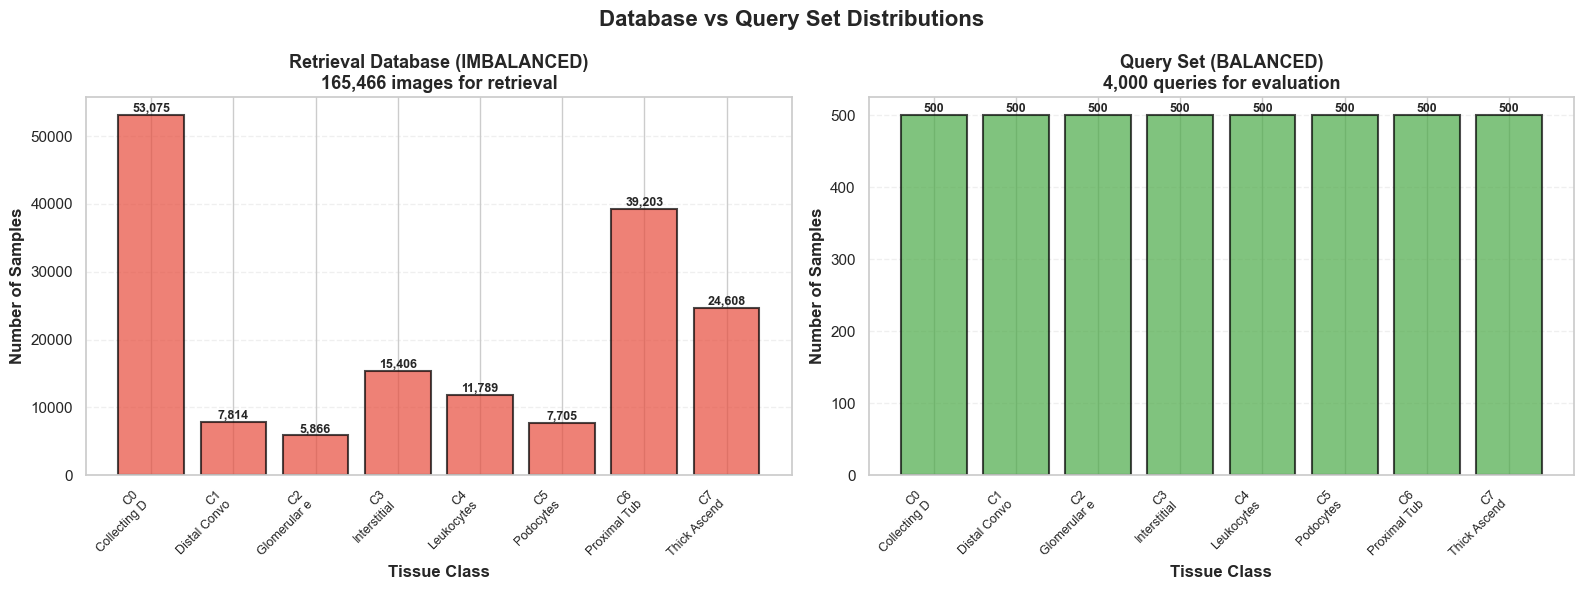

✓ Saved: results/figures/database_vs_queries.png


In [68]:
"""
Visualize the difference between database and query distributions
"""

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Database vs Query Set Distributions', fontsize=16, fontweight='bold')

# Left plot: Database (Training set - imbalanced)
ax1 = axes[0]
classes = sorted(train_dist.keys())
db_counts = [train_dist[c] for c in classes]
class_labels = [f"C{c}\n{loader.class_names[str(c)][:12]}" for c in classes]

bars1 = ax1.bar(range(len(classes)), db_counts, color='#e74c3c', alpha=0.7,
                edgecolor='black', linewidth=1.5)
ax1.set_xlabel('Tissue Class', fontsize=12, fontweight='bold')
ax1.set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
ax1.set_title('Retrieval Database (IMBALANCED)\n165,466 images for retrieval', 
              fontsize=13, fontweight='bold')
ax1.set_xticks(range(len(classes)))
ax1.set_xticklabels(class_labels, rotation=45, ha='right', fontsize=9)
ax1.grid(axis='y', alpha=0.3, linestyle='--')

# Add counts
for bar, count in zip(bars1, db_counts):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Right plot: Query set (balanced)
ax2 = axes[1]
query_dist = {}
for class_id in range(loader.n_classes):
    query_dist[class_id] = np.sum(balanced_labels == class_id)

query_counts = [query_dist[c] for c in classes]

bars2 = ax2.bar(range(len(classes)), query_counts, color="#4baa47", alpha=0.7,
                edgecolor='black', linewidth=1.5)
ax2.set_xlabel('Tissue Class', fontsize=12, fontweight='bold')
ax2.set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
ax2.set_title('Query Set (BALANCED)\n4,000 queries for evaluation', 
              fontsize=13, fontweight='bold')
ax2.set_xticks(range(len(classes)))
ax2.set_xticklabels(class_labels, rotation=45, ha='right', fontsize=9)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

# Add counts
for bar, count in zip(bars2, query_counts):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{count}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/database_vs_queries.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: results/figures/database_vs_queries.png")

## 12. Update Metadata

In [69]:
"""
Update metadata with imbalance handling strategy
"""

# Identify rare and common classes
class_counts = {int(k): int(v) for k, v in train_dist.items()}
sorted_classes = sorted(class_counts.items(), key=lambda x: x[1])

rare_classes = [cls for cls, _ in sorted_classes[:3]]  # Bottom 3
common_classes = [cls for cls, _ in sorted_classes[-3:]]  # Top 3

# Update metadata with comprehensive information
metadata.update({
    # Imbalance details
    'imbalance_severity': 'SEVERE',
    'imbalance_ratio': float(imbalance_ratio),
    'imbalance_note': 'Reflects realistic medical archive where rare cell types are underrepresented',
    
    # Class categorization
    'rare_classes': rare_classes,
    'common_classes': common_classes,
    'rare_class_names': {int(c): loader.class_names[str(c)] for c in rare_classes},
    'common_class_names': {int(c): loader.class_names[str(c)] for c in common_classes},
    
    # Evaluation strategy
    'evaluation_strategy': {
        'database': 'full_imbalanced',
        'database_size': int(len(loader.train_labels)),
        'queries': 'balanced_stratified',
        'query_size': int(len(balanced_labels)),
        'samples_per_class': int(len(balanced_labels) // loader.n_classes),
        'metrics': ['macro_averaged', 'weighted_averaged', 'per_class_breakdown'],
        'rationale': 'Balanced queries ensure fair evaluation; imbalanced database reflects reality'
    },
    
    # Expected challenges
    'expected_challenges': {
        'rare_class_retrieval': 'Models may struggle with classes having <10K samples',
        'class_confusion': 'Similar tissue types (e.g., tubule segments) may be confused',
        'metric_interpretation': 'Macro vs weighted averages will reveal imbalance effects'
    }
})

# Save updated metadata
with open('../data/processed/split_info.json', 'w') as f:
    json.dump(metadata, f, indent=2)


print("="*70)
print("✓ Metadata updated and saved")
print("="*70)

✓ Metadata updated and saved


## 13. Evaluation Strategy

In [70]:
print("="*70)
print("EVALUATION STRATEGY")
print("="*70)
print(f"""
APPROACH: Keep Database Realistic, Evaluate Fairly

📊 DATABASE (Retrieval Corpus):
   • Status: IMBALANCED (9.05:1 ratio)
   • Size: {metadata['database_size']:,} images
   • Rationale: Reflects real medical archive distribution
   • Rare classes ({', '.join([f"C{c}" for c in rare_classes])}): avg {np.mean([train_dist[c] for c in rare_classes]):,.0f} samples
   • Common classes ({', '.join([f"C{c}" for c in common_classes])}): avg {np.mean([train_dist[c] for c in common_classes]):,.0f} samples

🎯 QUERY SET (Evaluation):
   • Status: BALANCED (stratified sampling)
   • Size: {len(balanced_labels):,} queries
   • Per class: {len(balanced_labels) // loader.n_classes} queries
   • Rationale: Ensures each class is evaluated fairly

📈 METRICS TO REPORT:
   ✓ Macro-averaged Recall@K (treats all classes equally)
   ✓ Weighted-averaged Recall@K (accounts for database distribution)
   ✓ Per-class breakdown (reveals where models struggle)
   ✓ Rare class average vs Common class average
   
🔬 EXPECTED FINDINGS:
   • Domain-specific models (BiomedCLIP) should handle rare classes better
   • General models (CLIP, ResNet) may default to common classes
   • Macro vs weighted metrics will reveal this gap
   
📝 REPORT:
   "We maintain database realism (imbalanced) while ensuring evaluation 
   fairness (balanced queries). This reveals true model robustness for 
   clinically important but underrepresented tissue types."
""")


EVALUATION STRATEGY

APPROACH: Keep Database Realistic, Evaluate Fairly

📊 DATABASE (Retrieval Corpus):
   • Status: IMBALANCED (9.05:1 ratio)
   • Size: 165,466 images
   • Rationale: Reflects real medical archive distribution
   • Rare classes (C2, C5, C1): avg 7,128 samples
   • Common classes (C7, C6, C0): avg 38,962 samples

🎯 QUERY SET (Evaluation):
   • Status: BALANCED (stratified sampling)
   • Size: 4,000 queries
   • Per class: 500 queries
   • Rationale: Ensures each class is evaluated fairly

📈 METRICS TO REPORT:
   ✓ Macro-averaged Recall@K (treats all classes equally)
   ✓ Weighted-averaged Recall@K (accounts for database distribution)
   ✓ Per-class breakdown (reveals where models struggle)
   ✓ Rare class average vs Common class average

🔬 EXPECTED FINDINGS:
   • Domain-specific models (BiomedCLIP) should handle rare classes better
   • General models (CLIP, ResNet) may default to common classes
   • Macro vs weighted metrics will reveal this gap

📝 REPORT:
   "We main

## 14. Verification Checklist

In [71]:
# Quick verification 
print("Checking all required files exist...\n")

required_files = {
    'Figures': [
        '../results/figures/class_distribution.png',
        '../results/figures/sample_images.png',
        '../results/figures/class_imbalance.png',
        '../results/figures/database_vs_queries.png'
    ],
    'Data': [
        '../data/processed/split_info.json',
        '../data/processed/balanced_query_indices.npy',
        '../data/processed/balanced_query_labels.npy'
    ],
    'Metrics': [
        '../results/metrics/class_statistics.csv'
    ]
}

all_good = True
for category, files in required_files.items():
    print(f"{category}:")
    for f in files:
        exists = os.path.exists(f)
        status = "✓" if exists else "✗ MISSING"
        print(f"  {status} {f}")
        if not exists:
            all_good = False
    print()

if all_good:
    print("="*70)
    print("✅ ALL FILES CREATED SUCCESSFULLY!")
    print("="*70)
else:
    print("="*70)
    print("⚠️  Some files are missing. Re-run the cells above.")
    print("="*70)

Checking all required files exist...

Figures:
  ✓ ../results/figures/class_distribution.png
  ✓ ../results/figures/sample_images.png
  ✓ ../results/figures/class_imbalance.png
  ✓ ../results/figures/database_vs_queries.png

Data:
  ✓ ../data/processed/split_info.json
  ✓ ../data/processed/balanced_query_indices.npy
  ✓ ../data/processed/balanced_query_labels.npy

Metrics:
  ✓ ../results/metrics/class_statistics.csv

✅ ALL FILES CREATED SUCCESSFULLY!
